# BrushCue Example: Inked Filter

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/inked_filter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/inked-filter

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


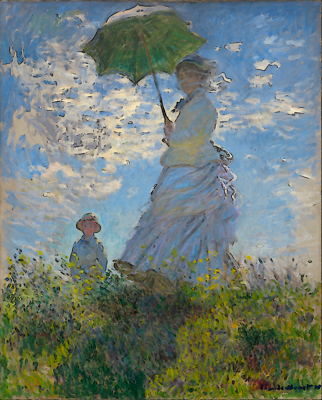

In [1]:
import io
from PIL import Image

import brushcue as bc

ink_amount = 0.6
line_width = 1.5
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
smoothed = input_image.median(3)
toned = smoothed.saturation_adjust(1.2)
graph = (
    smoothed.spacial_effect_shader(
        "let lo = image_bounds.xy + vec2<f32>(0.5);\nlet hi = image_bounds.zw - vec2<f32>(0.5);\nlet k = vec3<f32>(0.2126, 0.7152, 0.0722);\nlet w = line_width;\nlet tl = dot(sample(clamp(position + vec2<f32>(-w, -w), lo, hi)).rgb, k);\nlet t = dot(sample(clamp(position + vec2<f32>(0.0, -w), lo, hi)).rgb, k);\nlet tr = dot(sample(clamp(position + vec2<f32>(w, -w), lo, hi)).rgb, k);\nlet l = dot(sample(clamp(position + vec2<f32>(-w, 0.0), lo, hi)).rgb, k);\nlet r = dot(sample(clamp(position + vec2<f32>(w, 0.0), lo, hi)).rgb, k);\nlet bl = dot(sample(clamp(position + vec2<f32>(-w, w), lo, hi)).rgb, k);\nlet b = dot(sample(clamp(position + vec2<f32>(0.0, w), lo, hi)).rgb, k);\nlet br = dot(sample(clamp(position + vec2<f32>(w, w), lo, hi)).rgb, k);\nlet gx = (tr + 2.0 * r + br) - (tl + 2.0 * l + bl);\nlet gy = (bl + 2.0 * b + br) - (tl + 2.0 * t + tr);\nlet lo_edge = 0.7 - 0.55 * ink_amount;\nlet edge = smoothstep(lo_edge, lo_edge + 0.2, length(vec2<f32>(gx, gy)));\nlet ink = 1.0 - edge;\nreturn vec4<f32>(ink, ink, ink, 1.0);",
        "",
        (line_width * 2.0),
        bc.Dictionary.create()
        .add("ink_amount", ink_amount)
        .add("line_width", line_width)
        .add("image_bounds", input_bounds),
        bc.ColorRepresentation.srgb(),
    )
    .crop(input_bounds)
    .blend_multiply(toned)
    .crop(input_bounds)
)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
